# Plate-level morphometric variation

This notebook implements the plotting notes in the comparison notebook.
It reuses its image preprocessing, skeletonization and 5-pixel terminal-width
measurements. Each plate has equal weight in the width-distribution averages.
Bootstrap confidence intervals resample plates, not individual terminal widths.
Identical simulation replicates of the same input are excluded from aggregate plots.


### Seed-count display convention (2026-11-25)

Each white native-grid pixel is one seed. Fixed counts are recomputed from those
pixels when metadata is loaded: Fixed_18 = 57 and Fixed_19 = 37. The actual
`seed_count` is retained for calculations; `seed_count_plot` uses 1–26 and a final
position 27 labelled **>26**. Means and plate-bootstrap intervals pool all plates
in that final category. Branch-tip and skeleton-length summaries connect to the >26 endpoint, which is a pooled display category.
Grayscale and exploratory seed-count colors use the same overflow mapping; colorbars omit the crowded 26 tick and label the top endpoint >26.

Plots and vector-export cells were executed on 2026-11-25 using the reviewed
per-plate/width measurements, corrected seed-count metadata and pooled >26
summaries. Image measurements and cohorts were preserved. The vector PDFs and
companion plate/width/group-summary CSVs have been refreshed. Run each vector
export cell immediately after its preceding plot when regenerating figures.


Colony-area and branch-angle explorations (including their angle-enabled
collection) are preserved in
`Misc/notebook_sections/sim_to_exp_diffusion/controlnet_essential/morphometric_area_and_branch_angles.ipynb`.
This active notebook retains Figure 4C, Supplementary Figure 15C/D/E, Supplementary
Figure 16C, and the blue-colorbar absolute-difference replicate scatter plot.


The upper normalized-difference replicate scatter was moved to
`Misc/notebook_sections/sim_to_exp_diffusion/controlnet_essential/morphometric_replicate_normalized_difference.ipynb`.
The blue-colorbar absolute-difference scatter retains all shared setup needed
by the final variability-ratio panel.


In [2]:
import os
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.ndimage import distance_transform_edt
import matplotlib.ticker as ticker

from cldm.config import (
    DIFFUSION_FOLDER_TEST_FIXED,
    EXP_FOLDER_TEST,
    EXP_FOLDER_TEST_FIXED,
    FPATH,
    MAIN_FOLDER,
    SIM_FOLDER_TEST_FIXED_OUTPUT,
)

fm.fontManager.addfont(str(FPATH))
ARIAL_FONT_NAME = fm.FontProperties(fname=str(FPATH)).get_name()
plt.rcParams['font.family'] = ARIAL_FONT_NAME
from cldm.preprocess import (
    preprocess_experimental_backgroundblack,
    preprocess_experimental_backgroundblack_blackandwhite,
    preprocess_experimental_backgroundblack_blackandwhite_nocropping,
)
from cldm.morpho_features import (
    SkeletonConfig, endpoint_pixel_map, skeletonize_colony,
    summarize_skeleton,
)
from cldm.display import create_skeleton_overlay

from cldm.seed_counts import (
    load_seed_counts, add_seed_count_plot_columns, seed_count_positions,
    seed_count_label, summarize_seed_count_groups, plot_seed_count_summary,
    configure_seed_count_axis, configure_seed_count_colorbar,
)


In [3]:
# ======================== TUNABLE PARAMETERS ========================
SKELETON_CONFIG = SkeletonConfig(
    mask_smooth_sigma=1.25,
    mask_smooth_threshold=0.50,
    mask_min_object_px=64,
    mask_closing_radius_px=0,
    spur_factor=1.0,
    spur_min_px=2.0,
    radius_cap_px=8.0,
    max_prune_fraction=0.02,
    min_branches_for_pruning=5,
    blob_radius_factor=1.5,
    blob_min_radius_px=6.0,
    blob_min_core_area_px=50,
    blob_core_expansion_px=5,
    blob_interface_tolerance_px=4,
    blob_attachment_cluster_radius_px=2,
    blob_max_attachments=24,
    blob_min_attachments_for_hub=2,
    blob_path_cost_power=1.5,
    strand_radius_quantile=0.85,
)

TERMINAL_INSET_PX = 5.0
RANDOM_SEED = 42
PIXEL_SIZE = 10/25.92       # physical units per pixel, when calibrated
PHYSICAL_UNIT = 'mm'
SAVE_COMPARISON_CSV = None  # e.g. 'exp_diffusion_metrics.csv'
DIFFUSION_SAMPLE_INDEX_FIXED = 1  # which of the 3 diffusion samples per Fixed_N_M stem to use
# ===================================================================

In [3]:
def total_skeleton_length_px(skeleton):
    """Sum Skan path lengths across every connected colony in the plate.

    Skan measures pixel-center steps: horizontal/vertical = 1 px,
    diagonal = sqrt(2) px. No biological hub consolidation is needed.
    """
    _, branch_table = summarize_skeleton(skeleton)
    return float(branch_table['branch_distance'].sum())


def path_distance(coordinates):
    """Cumulative distance along an 8-connected skeleton path."""
    steps = np.diff(coordinates.astype(float), axis=0)
    return np.r_[0.0, np.cumsum(np.linalg.norm(steps, axis=1))]


def terminal_paths(skeleton_result):
    """Return one path starting at each final-skeleton endpoint."""
    skeleton = skeleton_result['final']
    endpoint_map = endpoint_pixel_map(skeleton)
    skan_skeleton, branch_table = summarize_skeleton(skeleton)
    paths = []

    for branch_index in range(len(branch_table)):
        coordinates = skan_skeleton.path_coordinates(branch_index).astype(int)
        if endpoint_map[tuple(coordinates[0])]:
            paths.append(coordinates)
        if endpoint_map[tuple(coordinates[-1])]:
            paths.append(coordinates[::-1])

    return paths


def terminal_widths(skeleton_result):
    """Measure terminal widths 5 pixels inward; skip shorter paths."""
    distance_map = distance_transform_edt(skeleton_result['mask'])
    records = []

    for tip_index, coordinates in enumerate(terminal_paths(skeleton_result)):
        inward_distance = path_distance(coordinates)
        if inward_distance[-1] < TERMINAL_INSET_PX:
            continue

        measurement_index = np.searchsorted(inward_distance, TERMINAL_INSET_PX)
        tip = coordinates[0]
        measurement = coordinates[measurement_index]
        width_px = 2 * distance_map[tuple(measurement)]

        records.append({
            'tip_index': tip_index,
            'tip_y': int(tip[0]),
            'tip_x': int(tip[1]),
            'measurement_y': int(measurement[0]),
            'measurement_x': int(measurement[1]),
            'width_px': float(width_px),
        })

    return pd.DataFrame(records, columns=['tip_index', 'tip_y', 'tip_x',
                                         'measurement_y', 'measurement_x', 'width_px'])


def image_metrics(binary_mask):
    """Calculate all four comparison metrics from one binary mask."""
    binary_mask = np.asarray(binary_mask, dtype=bool)
    skeleton_result = skeletonize_colony(binary_mask, config=SKELETON_CONFIG)
    widths = terminal_widths(skeleton_result)

    metrics = {
        'branch_tip_count': int(endpoint_pixel_map(skeleton_result['final']).sum()),
        'total_skeleton_length_px': total_skeleton_length_px(skeleton_result['final']),
        'valid_width_count': len(widths),
        'mean_terminal_width_px': widths['width_px'].mean(),
        'sd_terminal_width_px': widths['width_px'].std(ddof=1),
        'median_terminal_width_px': widths['width_px'].median(),
        'colony_area_px': int(binary_mask.sum()),
        'colony_area_fraction': float(binary_mask.mean()),
    }

    if PIXEL_SIZE is not None:
        metrics[f'total_skeleton_length_{PHYSICAL_UNIT}'] = (
            metrics['total_skeleton_length_px'] * PIXEL_SIZE
        )
        metrics[f'mean_terminal_width_{PHYSICAL_UNIT}'] = (
            metrics['mean_terminal_width_px'] * PIXEL_SIZE
        )
        metrics[f'colony_area_{PHYSICAL_UNIT}2'] = (
            metrics['colony_area_px'] * PIXEL_SIZE**2
        )

    return metrics, skeleton_result, widths


def load_experimental(stem):
    base_folder = EXP_FOLDER_TEST_FIXED if stem.startswith('Fixed_') else EXP_FOLDER_TEST
    path = os.path.join(base_folder, stem + '.TIF')
    image = preprocess_experimental_backgroundblack(path)
    mask = preprocess_experimental_backgroundblack_blackandwhite(path)
    return image, mask


def load_diffusion(stem):
    if stem.startswith('Fixed_'):
        path = os.path.join(DIFFUSION_FOLDER_TEST_FIXED, f'{stem}_{DIFFUSION_SAMPLE_INDEX_FIXED}.png')
    else:
        path = os.path.join(MAIN_FOLDER, stem + '.png')
    image_bgr = cv2.imread(path, cv2.IMREAD_COLOR)
    image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    mask = preprocess_experimental_backgroundblack_blackandwhite_nocropping(path)
    return image, mask


def plot_metric_overlay(ax, image, skeleton_result, widths, title):
    overlay = create_skeleton_overlay(image, skeleton_result['final'])
    tips_y, tips_x = np.where(endpoint_pixel_map(skeleton_result['final']))
    ax.imshow(overlay)
    ax.scatter(tips_x, tips_y, s=20, c='cyan', edgecolors='black', linewidths=0.3)
    ax.scatter(
        widths['measurement_x'], widths['measurement_y'],
        s=16, c='yellow', edgecolors='black', linewidths=0.3,
    )
    ax.set_title(title, fontsize=9)
    ax.axis('off')


In [4]:
def stem_sort_key(stem):
    """Sort numeric stems ('196_1') and Fixed stems ('Fixed_10_1') separately."""
    parts = stem.split('_')
    return (parts[0] == 'Fixed', tuple(int(value) for value in parts if value.isdigit()))


experimental_by_stem = {
    Path(filename).stem: filename
    for folder in (EXP_FOLDER_TEST, EXP_FOLDER_TEST_FIXED)
    for filename in os.listdir(folder)
    if filename.lower().endswith(('.tif', '.tiff'))
}
diffusion_by_stem = {
    Path(filename).stem: filename
    for filename in os.listdir(MAIN_FOLDER)
    if filename.lower().endswith('.png')
}
diffusion_by_stem.update({
    f'{filename.split("_")[0]}_{filename.split("_")[1]}_{filename.split("_")[2]}': filename
    for filename in os.listdir(DIFFUSION_FOLDER_TEST_FIXED)
    if filename.lower().endswith('.png') and filename.endswith(f'_{DIFFUSION_SAMPLE_INDEX_FIXED}.png')
})

paired_stems = sorted(experimental_by_stem.keys() & diffusion_by_stem.keys(), key=stem_sort_key)
print(f'{len(paired_stems)} matched experiment–diffusion image pairs')


132 matched experiment–diffusion image pairs


In [5]:
from cldm.config import SIM_FOLDER_TEST
from cldm.preprocess import preprocess_simulation

# ================= SIMULATION PARAMETERS =================
SIMULATION_THRESHOLD = 110
SIMULATION_BLUR_KERNEL = 5  # set to 1 to disable this preprocessing blur
# =========================================================

simulation_by_stem = {
    Path(filename).stem: filename
    for filename in os.listdir(SIM_FOLDER_TEST)
    if filename.lower().endswith(('.tif', '.tiff'))
}
# Fixed_N_1 and Fixed_N_2 share the same simulation output (one config, multiple experimental replicates).
fixed_simulation_by_seed_number = {
    Path(filename).stem.split('_')[-1]: filename
    for filename in os.listdir(SIM_FOLDER_TEST_FIXED_OUTPUT)
    if filename.lower().endswith('.png')
}
simulation_by_stem.update({
    stem: fixed_simulation_by_seed_number[stem.split('_')[1]]
    for stem in paired_stems
    if stem.startswith('Fixed_') and stem.split('_')[1] in fixed_simulation_by_seed_number
})
three_way_stems = [stem for stem in paired_stems if stem in simulation_by_stem]
print(f'{len(three_way_stems)} matched experiment–diffusion–simulation images')


def load_simulation(stem):
    base_folder = SIM_FOLDER_TEST_FIXED_OUTPUT if stem.startswith('Fixed_') else SIM_FOLDER_TEST
    path = os.path.join(base_folder, simulation_by_stem[stem])
    grayscale = preprocess_simulation(path)
    blurred = cv2.GaussianBlur(
        grayscale, (SIMULATION_BLUR_KERNEL, SIMULATION_BLUR_KERNEL), 0
    )
    mask = blurred > SIMULATION_THRESHOLD
    display_image = mask.astype(np.uint8) * 255
    return display_image, mask


132 matched experiment–diffusion–simulation images


In [4]:
import json
from cldm.config import SEED_FOLDER_TEST_SEEDINFO_COMBINED, SIM_FOLDER_TEST_FIXED_INPUT

# ===================== PLOT PARAMETERS =====================
WIDTH_BIN_SIZE_PX = 1.0
KDE_BANDWIDTH_PX = 1.0   # same absolute bandwidth for every plate
KDE_GRID_POINTS = 300
KDE_TITLE_FONTSIZE = 38
KDE_LABEL_FONTSIZE = 38
KDE_TICK_FONTSIZE = 38
KDE_LEGEND_FONTSIZE = 38
METRIC_PLOT_LABEL_FONTSIZE = 48
METRIC_PLOT_TICK_FONTSIZE = 44
METRIC_PLOT_LEGEND_FONTSIZE = 42
KDE_TRACE_OPACITY = 0.35
KDE_TRACE_GRAY_MIN = 0.20
KDE_TRACE_GRAY_MAX = 1.2
BOOTSTRAP_REPEATS = 1000
CONFIDENCE_LEVEL = 0.95
EXCLUDE_DUPLICATE_SIMULATIONS = True
MAX_PLATES_PER_SOURCE = None  # None: all; set to 3 for a quick check
FIGURE_OUTPUT_DIR = None      # e.g. 'outputs/morphometric_variation'
# ==========================================================

SOURCE_ORDER = ['Simulation', 'Experiment', 'Diffusion']
SOURCE_COLORS = {'Simulation': 'tab:orange', 'Experiment': 'tab:green', 'Diffusion': '#1AA3D6'}
SOURCE_MARKERS = {'Simulation': '^', 'Experiment': 'o', 'Diffusion': 's'}

seed_counts = load_seed_counts(
    SEED_FOLDER_TEST_SEEDINFO_COMBINED, SIM_FOLDER_TEST_FIXED_INPUT
)


## Collect one row per plate and retain its terminal widths

The table records the number of eligible width measurements, median width, IQR,
sample SD, CV (SD/mean), total tips, skeleton length and area. Plates without eligible
widths contribute to tip plots but are omitted from width plots. Tip counts include
all final-skeleton endpoints, including those excluded from width measurement.


In [ ]:
plate_records = []
width_tables = []
previous_simulation_masks = {}
loaders = {'Simulation': load_simulation, 'Experiment': load_experimental, 'Diffusion': load_diffusion}
selected_stems = three_way_stems[:MAX_PLATES_PER_SOURCE]

for source in SOURCE_ORDER:
    for image_number, stem in enumerate(selected_stems, start=1):
        # Progress is printed before the duplicate-simulation skip so skipped files still count.
        if image_number % 10 == 0 or image_number == len(selected_stems):
            print(f'{source}: processed {image_number}/{len(selected_stems)} files')

        image, mask = loaders[source](stem)

        # Simulated _1 and _2 files may be copies of the same simulation.
        if source == 'Simulation' and EXCLUDE_DUPLICATE_SIMULATIONS:
            prefix = stem.rsplit('_', 1)[0]  # '196_1' -> '196'; 'Fixed_10_1' -> 'Fixed_10'
            earlier_masks = previous_simulation_masks.setdefault(prefix, [])
            if any(np.array_equal(mask, previous) for previous in earlier_masks):
                continue
            earlier_masks.append(mask.copy())

        metrics, skeleton_result, widths = image_metrics(mask)
        values = widths['width_px'].to_numpy(float)
        seed_count = seed_counts[stem + '.png']
        mean_width = values.mean() if len(values) else np.nan
        sd_width = values.std(ddof=1) if len(values) > 1 else np.nan
        iqr = np.percentile(values, 75) - np.percentile(values, 25) if len(values) else np.nan

        plate_records.append({
            'source': source, 'image_id': stem, 'seed_count': seed_count,
            **metrics,
            'width_iqr_px': iqr,
            'width_cv': sd_width / mean_width if len(values) else np.nan,
            'tips_per_seed': metrics['branch_tip_count'] / seed_count,
            'tips_per_100px_length': 100 * metrics['branch_tip_count'] / metrics['total_skeleton_length_px'],
        })
        width_tables.append(widths.assign(source=source, image_id=stem, seed_count=seed_count))

plate_df = pd.DataFrame(plate_records)
terminal_width_df = pd.concat(width_tables, ignore_index=True)
add_seed_count_plot_columns(plate_df)
add_seed_count_plot_columns(terminal_width_df)
display(plate_df)
display(plate_df.groupby('source')[['branch_tip_count', 'valid_width_count']].agg(['count', 'mean']))


In [6]:
def bootstrap_mean_interval(values):
    """Resample whole plate rows and return a confidence interval for the mean."""
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(RANDOM_SEED)
    indices = rng.integers(0, len(values), size=(BOOTSTRAP_REPEATS, len(values)))
    bootstrap_means = values[indices].mean(axis=1)
    tail = (1 - CONFIDENCE_LEVEL) / 2
    return np.quantile(bootstrap_means, [tail, 1 - tail], axis=0)


def save_figure(fig, name):
    if FIGURE_OUTPUT_DIR is not None:
        directory = Path(FIGURE_OUTPUT_DIR)
        directory.mkdir(parents=True, exist_ok=True)
        fig.savefig(directory / (name + '.png'), dpi=300, bbox_inches='tight')
        fig.savefig(directory / (name + '.pdf'), bbox_inches='tight')


def plot_plate_values(ax, column, ylabel):
    """Violin, box and individual plate points; diamond is mean with plate-bootstrap CI."""
    rng = np.random.default_rng(RANDOM_SEED)
    summary = []
    for position, source in enumerate(SOURCE_ORDER):
        values = plate_df.loc[plate_df['source'] == source, column].dropna().to_numpy()
        if len(values) == 0:
            continue
        if len(values) > 1 and np.ptp(values) > 0:
            violin = ax.violinplot(values, positions=[position], widths=0.8, showextrema=False)
            violin['bodies'][0].set_facecolor(SOURCE_COLORS[source])
            violin['bodies'][0].set_alpha(0.2)
        ax.boxplot(values, positions=[position], widths=0.2, showfliers=False)
        ax.scatter(position + rng.uniform(-0.15, 0.15, len(values)), values,
                   s=20, color=SOURCE_COLORS[source], alpha=0.65)
        lower, upper = bootstrap_mean_interval(values)
        mean = values.mean()
        ax.errorbar(position + 0.3, mean, yerr=[[mean - lower], [upper - mean]],
                    fmt='D', color='black', capsize=3)
        summary.append({'source': source, 'metric': column, 'plate_count': len(values),
                        'mean': mean, 'ci_lower': lower, 'ci_upper': upper})
    ax.set_xticks(range(len(SOURCE_ORDER)), SOURCE_ORDER)
    ax.set_ylabel(ylabel)
    return summary


In [7]:
# Plot units: physical when PIXEL_SIZE is set, otherwise pixels. Rerun this cell after changing PIXEL_SIZE.
LENGTH_SCALE = PIXEL_SIZE if PIXEL_SIZE is not None else 1.0
LENGTH_UNIT = PHYSICAL_UNIT if PIXEL_SIZE is not None else 'px'

plate_df['median_terminal_width_plot'] = plate_df['median_terminal_width_px'] * LENGTH_SCALE
plate_df['width_iqr_plot'] = plate_df['width_iqr_px'] * LENGTH_SCALE
plate_df['tips_per_unit_length'] = plate_df['tips_per_100px_length'] / 100 / LENGTH_SCALE
terminal_width_df['width_plot'] = terminal_width_df['width_px'] * LENGTH_SCALE


## Complete terminal-width distributions

Thin grayscale lines show each plate (lighter = fewer seeds). Thick colored lines
show the arithmetic mean of plate KDEs, and the shaded intervals bootstrap whole
plate curves. All sources use the same bandwidth. KDEs use reflection at zero so
the density stays on nonnegative widths. A dotted red line marks the peak of each
source's plate-averaged KDE.


Grayscale represents counts 1–26, with all higher counts shown as **>26**.

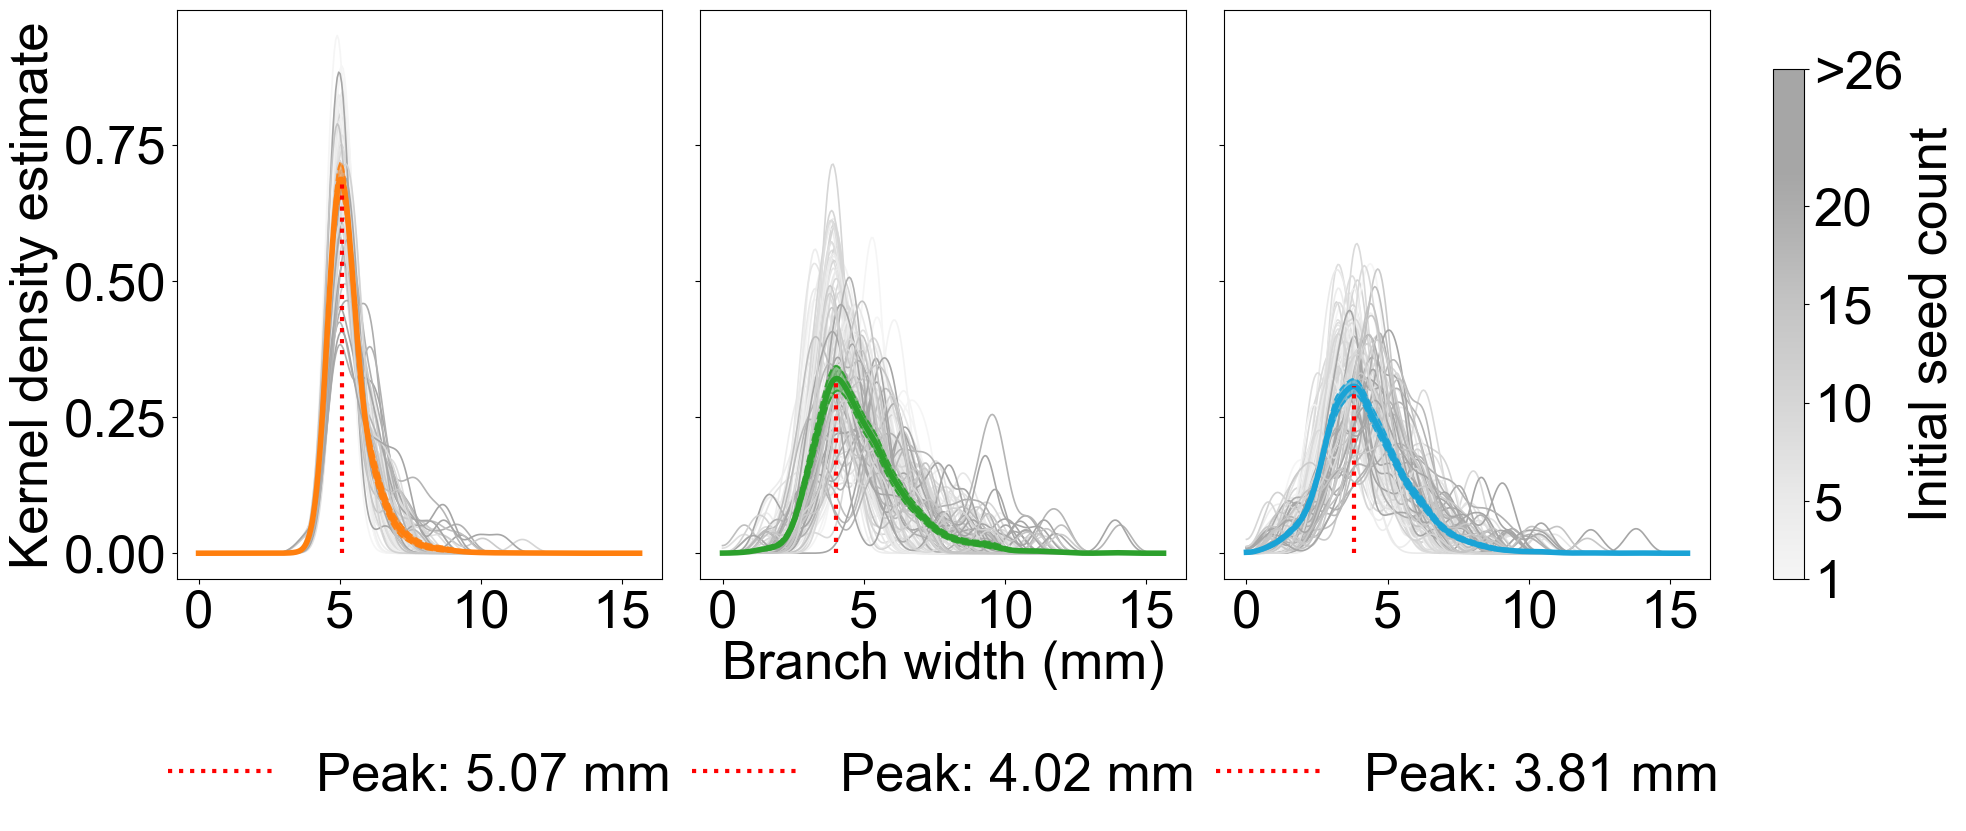

In [8]:
bandwidth = KDE_BANDWIDTH_PX * LENGTH_SCALE
maximum_width = terminal_width_df['width_plot'].max()
width_grid = np.linspace(0, maximum_width + 4 * bandwidth, KDE_GRID_POINTS)
seed_normalizer = plt.Normalize(1, 27)  # 27 is the >26 display category, not an actual count

# Pre-blend one shared grayscale map against white. Using the resulting
# opaque colors for both traces and colorbar makes their appearance match.
trace_colors = plt.cm.Greys(np.linspace(
    KDE_TRACE_GRAY_MIN, KDE_TRACE_GRAY_MAX, 256
))
trace_colors[:, :3] = (
    (1 - KDE_TRACE_OPACITY)
    + KDE_TRACE_OPACITY * trace_colors[:, :3]
)
trace_colormap = ListedColormap(trace_colors, name='plate_trace_greys')

fig, axes = plt.subplots(1, 3, figsize=(21, 8.5), sharex=True, sharey=True)
distribution_records = []
peak_handles = []
peak_labels = []

for column, source in enumerate(SOURCE_ORDER):
    densities = []
    source_widths = terminal_width_df[terminal_width_df['source'] == source]

    for stem, terminals in source_widths.groupby('image_id'):
        values = terminals['width_plot'].to_numpy()
        # Fixed-bandwidth Gaussian density, reflected at the zero boundary.
        distance = (width_grid[:, None] - values[None, :]) / bandwidth
        reflected = (width_grid[:, None] + values[None, :]) / bandwidth
        density = (np.exp(-distance**2 / 2) + np.exp(-reflected**2 / 2)).mean(axis=1)
        density /= np.sqrt(2 * np.pi) * bandwidth

        seed_count = terminals['seed_count'].iloc[0]
        gray = trace_colormap(seed_normalizer(seed_count_positions(seed_count)))
        axes[column].plot(
            width_grid, density, color=gray, lw=1.2, alpha=1.0, zorder=1,
        )
        densities.append(density)

    curves = np.asarray(densities)
    lower, upper = bootstrap_mean_interval(curves)
    average = curves.mean(axis=0)
    peak_index = int(np.nanargmax(average))
    peak_width = width_grid[peak_index]
    peak_height = average[peak_index]

    axes[column].fill_between(
        width_grid, lower, upper, color=SOURCE_COLORS[source], alpha=0.45,
        zorder=2,
    )
    axes[column].plot(
        width_grid, lower, color=SOURCE_COLORS[source], lw=1.5,
        linestyle='--', alpha=0.9, zorder=2.5,
    )
    axes[column].plot(
        width_grid, upper, color=SOURCE_COLORS[source], lw=1.5,
        linestyle='--', alpha=0.9, zorder=2.5,
    )
    axes[column].plot(
        width_grid, average, color=SOURCE_COLORS[source], lw=4, zorder=3,
    )
    peak_handle = axes[column].vlines(
        peak_width, ymin=0, ymax=peak_height, color='red',
        linestyle=':', linewidth=3, zorder=4,
    )

    # increase x tick counts for better readability
    axes[column].xaxis.set_major_locator(ticker.MultipleLocator(5))
    peak_handles.append(peak_handle)
    peak_labels.append(f'Peak: {peak_width:.2f} {LENGTH_UNIT}')
    # axes[column].set_title(
    #     f'{source} | {len(curves)} plates', fontsize=KDE_TITLE_FONTSIZE,
    # )
    axes[column].tick_params(axis='both', labelsize=KDE_TICK_FONTSIZE)
    # do legend at bottom of graph 
    # axes[column].legend(loc='lower center', bbox_to_anchor=(0.5, -0.5), fontsize=KDE_LEGEND_FONTSIZE, frameon=False)

    distribution_records.append(pd.DataFrame({
        'source': source, 'method': 'KDE',
        f'width_{LENGTH_UNIT}': width_grid,
        'mean_density': average, 'ci_lower': lower, 'ci_upper': upper,
        'peak_width': peak_width,
    }))



axes[0].set_ylabel(
    f'Kernel density estimate', fontsize=KDE_LABEL_FONTSIZE,
)
fig.supxlabel(
    f'Branch width ({LENGTH_UNIT})',
    x=0.495, y=0.16, fontsize=KDE_LABEL_FONTSIZE,
)
fig.subplots_adjust(left=0.13, right=0.86, bottom=0.29, top=0.96, wspace=0.08)
colorbar_axis = fig.add_axes([0.89, 0.29, 0.015, 0.60])
colorbar = fig.colorbar(
    plt.cm.ScalarMappable(norm=seed_normalizer, cmap=trace_colormap),
    cax=colorbar_axis,
)
for ax, peak_handle, peak_label in zip(axes, peak_handles, peak_labels):
    ax.legend(
        [peak_handle], [peak_label],
        loc='upper center', bbox_to_anchor=(0.5, -0.22),
        fontsize=KDE_LEGEND_FONTSIZE, frameon=False,
    )

configure_seed_count_colorbar(colorbar)
colorbar.set_label('Initial seed count', fontsize=KDE_LABEL_FONTSIZE)
colorbar.ax.tick_params(labelsize=KDE_TICK_FONTSIZE)
save_figure(fig, 'plate_width_distributions')
plt.show()
width_distribution_df = pd.concat(distribution_records, ignore_index=True)




In [9]:
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Vector PDF export: Fig. 4C — plate-level branch-width KDEs
# Run immediately after the preceding plotting/analysis cell.
from pathlib import Path
import runpy as _vector_runpy

# Locate the project from the notebook working directory; no sys.path changes.
VECTOR_PROJECT_ROOT = next(
    _p for _p in (Path.cwd(), *Path.cwd().parents)
    if (_p / 'figure_exports').is_dir()
)
save_vector_pdf = vars(_figure_exports)['save_vector_pdf']
VECTOR_DIR = VECTOR_PROJECT_ROOT / 'sim_to_exp_diffusion' / 'vector based plots'

save_vector_pdf(fig, VECTOR_DIR / 'Fig4C_branch_width_distributions.pdf')


Saved vector PDF: /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/vector based plots/Fig4C_branch_width_distributions.pdf


PosixPath('/hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/vector based plots/Fig4C_branch_width_distributions.pdf')

## Within-plate width variation

The coefficient of variation (sample SD / mean terminal width) describes width
heterogeneity within each plate. Every point is one plate; a black diamond and
vertical error bar indicate the group mean and its plate-bootstrap confidence
interval.


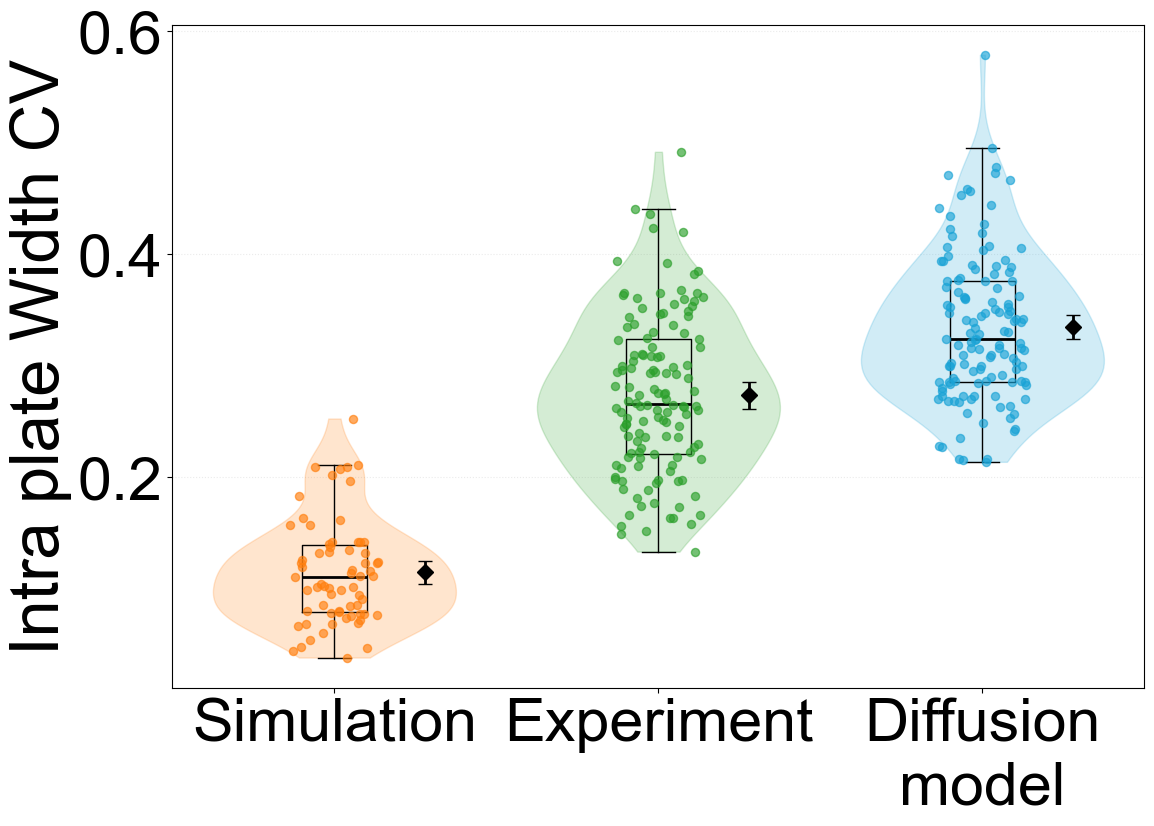

,source,metric,plate_count,mean,ci_lower,ci_upper
0,Simulation,width_cv,67,0.114693,0.103891,0.125309
1,Experiment,width_cv,132,0.273915,0.261176,0.285422
2,Diffusion,width_cv,132,0.334132,0.323376,0.345406


In [10]:
fig, ax = plt.subplots(figsize=(12, 8.5))
rng = np.random.default_rng(RANDOM_SEED)
variation_summary = []

for position, source in enumerate(SOURCE_ORDER):
    values = (
        plate_df.loc[plate_df['source'] == source, 'width_cv']
        .dropna().to_numpy(float)
    )
    if len(values) == 0:
        continue

    if len(values) > 1 and np.ptp(values) > 0:
        violin = ax.violinplot(
            values, positions=[position], vert=True, widths=0.75,
            showextrema=False,
        )
        violin['bodies'][0].set_facecolor(SOURCE_COLORS[source])
        violin['bodies'][0].set_edgecolor(SOURCE_COLORS[source])
        violin['bodies'][0].set_alpha(0.20)

    ax.boxplot(
        values, positions=[position], vert=True, widths=0.20,
        showfliers=False, patch_artist=False,
        medianprops={'color': 'black', 'linewidth': 2},
    )
    ax.scatter(
        position + rng.uniform(-0.14, 0.14, len(values)), values,
        s=34, color=SOURCE_COLORS[source], alpha=0.65, zorder=3,
    )

    lower, upper = bootstrap_mean_interval(values)
    mean = values.mean()
    ax.errorbar(
        position + 0.28, mean,
        yerr=[[mean - lower], [upper - mean]],
        fmt='D', color='black', markersize=8, linewidth=2, capsize=5,
        zorder=4,
    )
    variation_summary.append({
        'source': source, 'metric': 'width_cv', 'plate_count': len(values),
        'mean': mean, 'ci_lower': lower, 'ci_upper': upper,
    })

ax.set_xticks(
    range(len(SOURCE_ORDER)),
    ['Simulation', 'Experiment', 'Diffusion\nmodel'],
    fontsize=METRIC_PLOT_TICK_FONTSIZE,
)
ax.set_ylabel('Intra plate Width CV', fontsize=METRIC_PLOT_LABEL_FONTSIZE)
ax.tick_params(axis='y', labelsize=METRIC_PLOT_TICK_FONTSIZE)
ax.grid(axis='y', linestyle=':', alpha=0.25)
ax.set_axisbelow(True)
fig.subplots_adjust(left=0.16, right=0.97, bottom=0.18, top=0.96)
save_figure(fig, 'intra_plate_width_cv')
plt.show()
variation_summary_df = pd.DataFrame(variation_summary)
display(variation_summary_df)


In [11]:
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Vector PDF export: Supp. Fig. 15C — intra-plate width CV
# Run immediately after the preceding plotting/analysis cell.
from pathlib import Path
import runpy as _vector_runpy

# Locate the project from the notebook working directory; no sys.path changes.
VECTOR_PROJECT_ROOT = next(
    _p for _p in (Path.cwd(), *Path.cwd().parents)
    if (_p / 'figure_exports').is_dir()
)
save_vector_pdf = vars(_figure_exports)['save_vector_pdf']
VECTOR_DIR = VECTOR_PROJECT_ROOT / 'sim_to_exp_diffusion' / 'vector based plots'

save_vector_pdf(fig, VECTOR_DIR / 'SuppFig15C_intra_plate_width_cv.pdf')


Saved vector PDF: /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/vector based plots/SuppFig15C_intra_plate_width_cv.pdf


PosixPath('/hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/vector based plots/SuppFig15C_intra_plate_width_cv.pdf')

## Branch tips versus initial seed count

All endpoints contribute to these counts. Colors and markers distinguish sources;
faint points are individual plates. The connected markers show means at each seed
count, with confidence intervals obtained by resampling the plates at that count.


Counts above 26 are pooled in the **>26** display category; actual counts remain in the plate tables.

The >26 mean/error-bar marker is connected to the preceding numeric group as a visual guide.

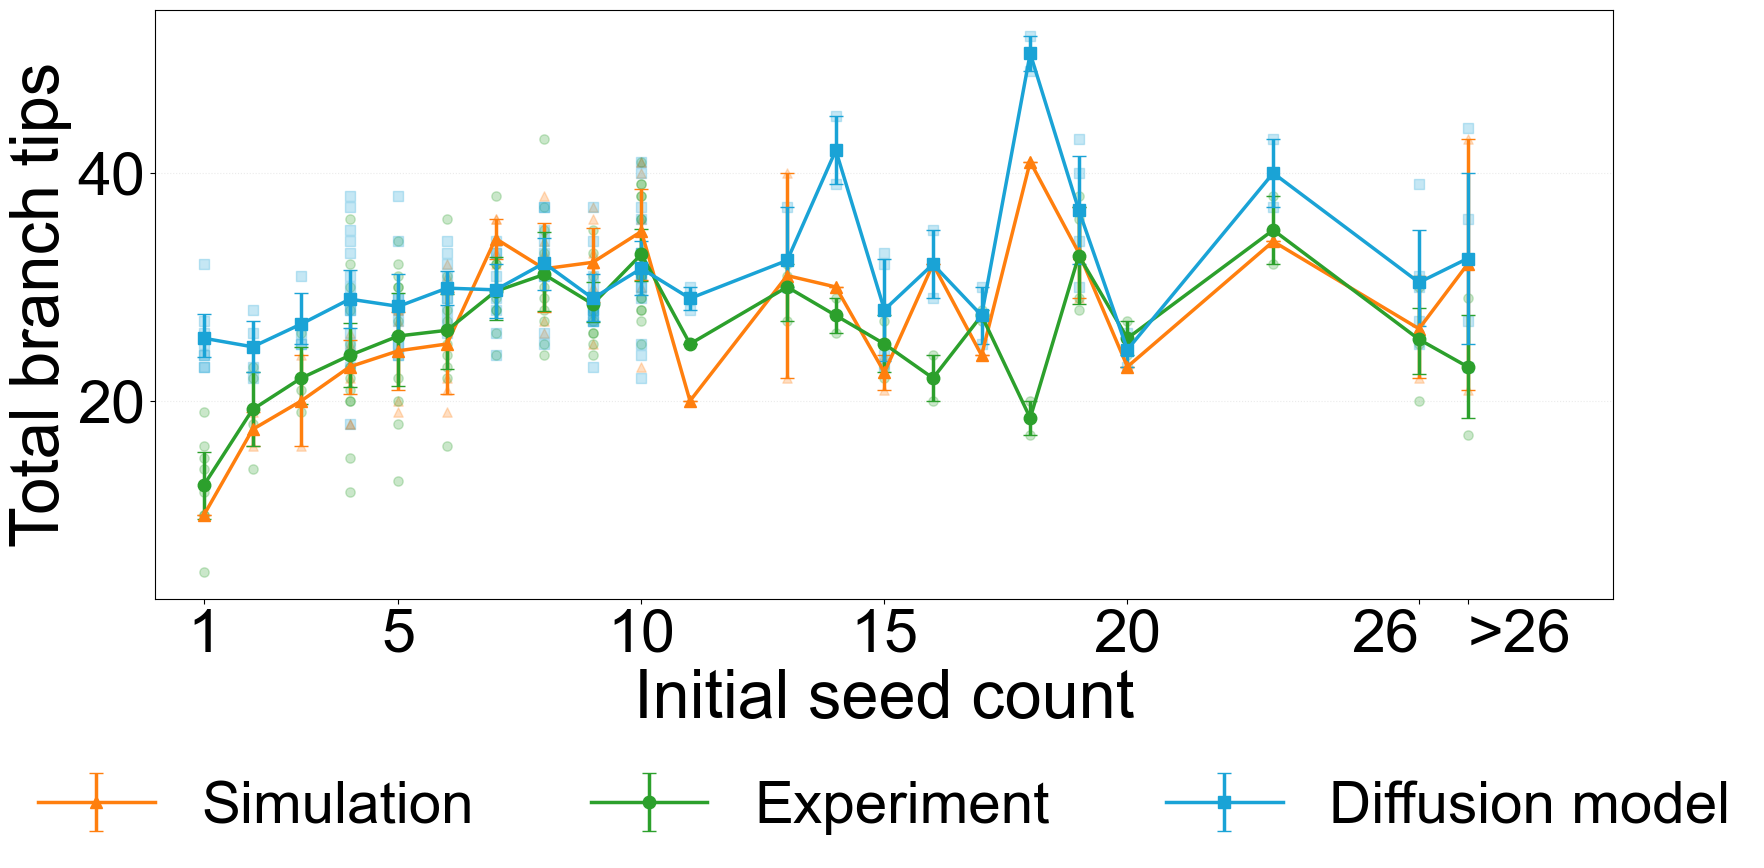

,source,metric,seed_count_plot,seed_count_group,actual_seed_count_min,actual_seed_count_max,plate_count,mean,sd,ci_lower,ci_upper
0,Simulation,branch_tip_count,1,1,1,1,4,10.00,0.000000,10.000000,10.000000
1,Simulation,branch_tip_count,2,2,2,2,2,17.50,2.121320,16.000000,19.000000
2,Simulation,branch_tip_count,3,3,3,3,2,20.00,5.656854,16.000000,24.000000
3,Simulation,branch_tip_count,4,4,4,4,8,23.00,3.779645,20.621875,25.378125
4,Simulation,branch_tip_count,5,5,5,5,5,24.40,4.505552,21.000000,27.800000
...,...,...,...,...,...,...,...,...,...,...,...
61,Diffusion,branch_tip_count,19,19,19,19,4,36.75,5.852350,32.000000,41.500000
62,Diffusion,branch_tip_count,20,20,20,20,2,24.50,2.121320,23.000000,26.000000
63,Diffusion,branch_tip_count,23,23,23,23,2,40.00,4.242641,37.000000,43.000000
64,Diffusion,branch_tip_count,26,26,26,26,5,30.40,5.366563,26.600000,35.000000


In [12]:
tips_by_seed_df = summarize_seed_count_groups(
    plate_df, 'branch_tip_count', SOURCE_ORDER, bootstrap_mean_interval
)
fig, ax = plt.subplots(figsize=(18, 9.5))

for source in SOURCE_ORDER:
    plates = plate_df[plate_df['source'] == source]
    ax.scatter(
        plates['seed_count_plot'], plates['branch_tip_count'],
        color=SOURCE_COLORS[source], marker=SOURCE_MARKERS[source],
        s=45, alpha=0.25, zorder=1,
    )
    summary = tips_by_seed_df[tips_by_seed_df['source'] == source].sort_values('seed_count_plot')
    source_label = 'Diffusion model' if source == 'Diffusion' else source
    plot_seed_count_summary(
        ax, summary, connect_overflow=True,
        color=SOURCE_COLORS[source], marker=SOURCE_MARKERS[source],
        linewidth=2.5, markersize=9, capsize=5, label=source_label, zorder=3,
    )

configure_seed_count_axis(ax)
ax.set_xlabel('Initial seed count', fontsize=METRIC_PLOT_LABEL_FONTSIZE)
ax.set_ylabel('Total branch tips', fontsize=METRIC_PLOT_LABEL_FONTSIZE)
ax.tick_params(axis='both', labelsize=METRIC_PLOT_TICK_FONTSIZE)
ax.grid(axis='y', linestyle=':', alpha=0.25)
ax.set_axisbelow(True)
ax.legend(
    loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=len(SOURCE_ORDER),
    fontsize=METRIC_PLOT_LEGEND_FONTSIZE, frameon=False,
)
fig.subplots_adjust(left=0.16, right=0.97, bottom=0.34, top=0.96)
save_figure(fig, 'tips_vs_seed_count')
plt.show()
display(tips_by_seed_df)


In [14]:
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Vector PDF export: Supp. Fig. 15D — branch tips versus initial seeds
# Run immediately after the preceding plotting/analysis cell.
from pathlib import Path
import runpy as _vector_runpy

# Locate the project from the notebook working directory; no sys.path changes.
VECTOR_PROJECT_ROOT = next(
    _p for _p in (Path.cwd(), *Path.cwd().parents)
    if (_p / 'figure_exports').is_dir()
)
save_vector_pdf = vars(_figure_exports)['save_vector_pdf']
VECTOR_DIR = VECTOR_PROJECT_ROOT / 'sim_to_exp_diffusion' / 'vector based plots'

save_vector_pdf(fig, VECTOR_DIR / 'SuppFig15D_tips_vs_seed_count.pdf')


Saved vector PDF: /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/vector based plots/SuppFig15D_tips_vs_seed_count.pdf


PosixPath('/hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/vector based plots/SuppFig15D_tips_vs_seed_count.pdf')

## Total branch length across the plate

Total length sums the final skeleton paths across all connected colonies, including
terminal paths, junction-to-junction paths and loops. Horizontal and vertical steps
measure 1 pixel; diagonal steps measure √2 pixels. The result is a centerline length,
not a skeleton-pixel count or a straight distance between endpoints.

The plot relates total length to initial seed count. Faint points are individual
plates; connected markers show means with confidence intervals from resampling plates.
Set PIXEL_SIZE above to convert length into physical units; rerun collection afterward.


Counts above 26 are pooled in the **>26** display category; actual counts remain in the plate tables.

The >26 mean/error-bar marker is connected to the preceding count group as a visual guide.

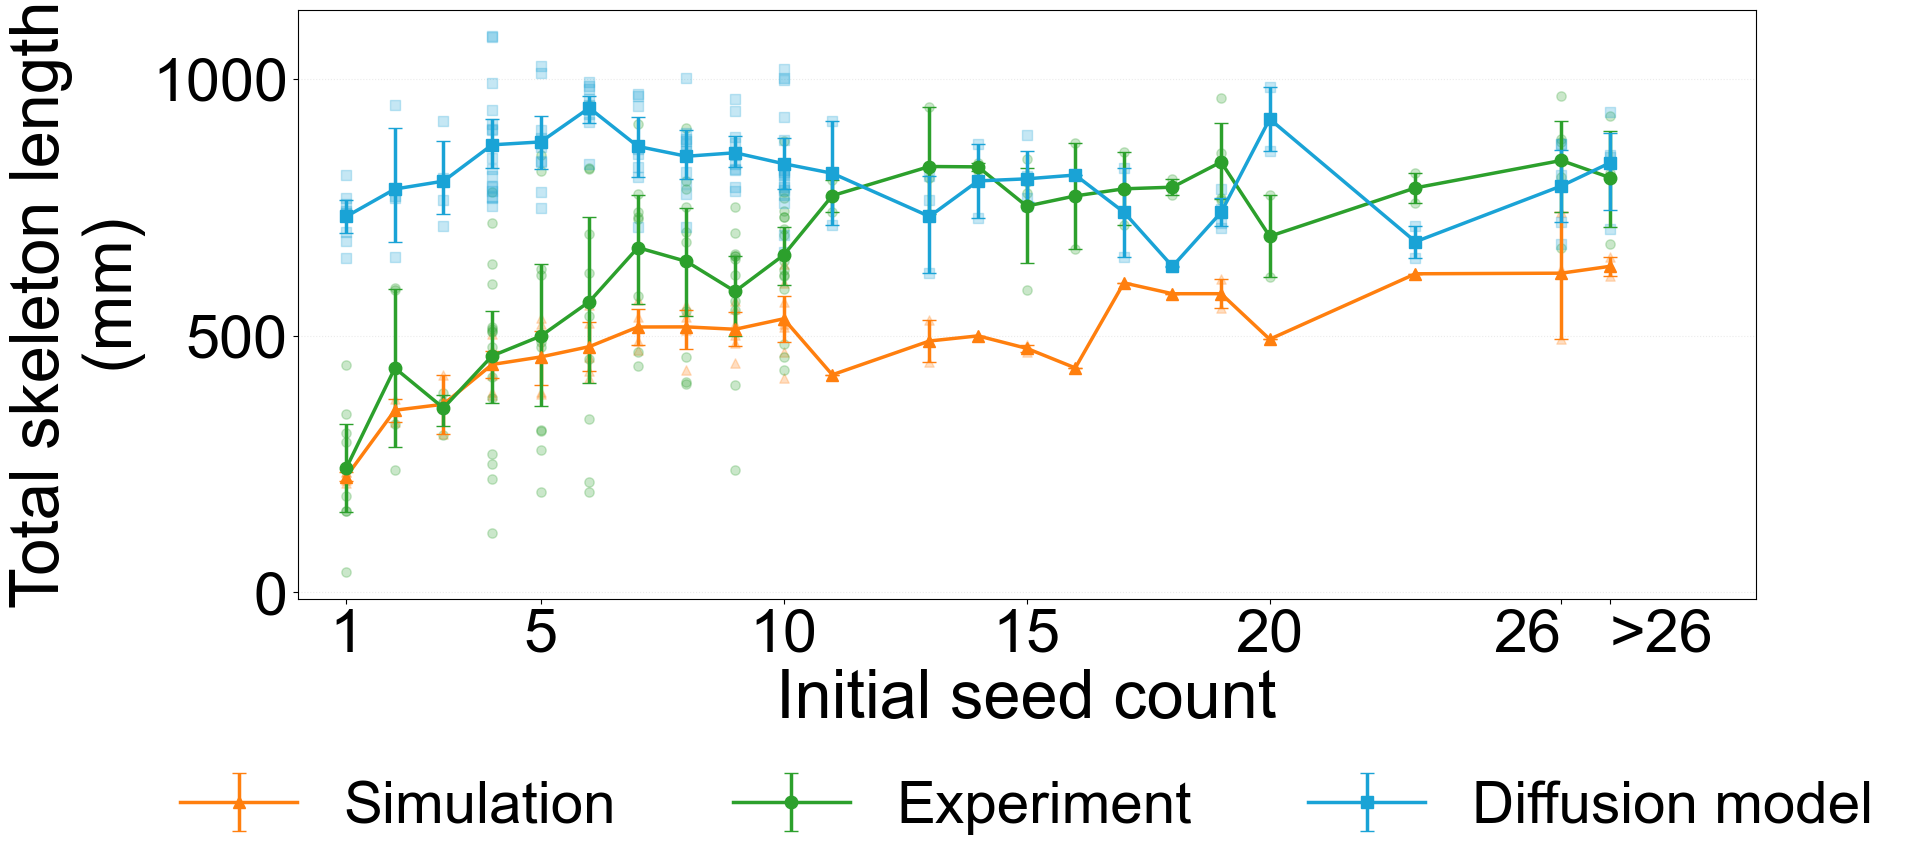

,source,metric,seed_count_plot,seed_count_group,actual_seed_count_min,actual_seed_count_max,plate_count,mean,sd,ci_lower,ci_upper
0,Simulation,total_skeleton_length_mm,1,1,1,1,4,225.355281,10.703229,216.341407,234.369154
1,Simulation,total_skeleton_length_mm,2,2,2,2,2,354.672761,31.538865,332.371416,376.974106
2,Simulation,total_skeleton_length_mm,3,3,3,3,2,366.373543,80.806633,309.234624,423.512461
3,Simulation,total_skeleton_length_mm,4,4,4,4,8,443.829471,41.686295,417.144225,470.868961
4,Simulation,total_skeleton_length_mm,5,5,5,5,5,458.509255,70.195541,403.394411,510.019885
...,...,...,...,...,...,...,...,...,...,...,...
61,Diffusion,total_skeleton_length_mm,19,19,19,19,4,740.065287,33.669175,714.560508,768.509701
62,Diffusion,total_skeleton_length_mm,20,20,20,20,2,922.063906,89.058881,859.089767,985.038045
63,Diffusion,total_skeleton_length_mm,23,23,23,23,2,682.953501,44.462273,651.513926,714.393076
64,Diffusion,total_skeleton_length_mm,26,26,26,26,5,791.581539,89.100792,722.015191,860.931051


In [15]:
# Reuse the lengths already collected in plate_df.
length_column = (
    f'total_skeleton_length_{PHYSICAL_UNIT}'
    if PIXEL_SIZE is not None else 'total_skeleton_length_px'
)
length_unit = PHYSICAL_UNIT if PIXEL_SIZE is not None else 'px'
total_length_by_seed_df = summarize_seed_count_groups(
    plate_df, length_column, SOURCE_ORDER, bootstrap_mean_interval
)
fig, ax = plt.subplots(figsize=(18, 9.5))
for source in SOURCE_ORDER:
    plates = plate_df[plate_df['source'] == source]
    ax.scatter(
        plates['seed_count_plot'], plates[length_column],
        color=SOURCE_COLORS[source], marker=SOURCE_MARKERS[source],
        s=45, alpha=0.25, zorder=1,
    )
    summary = total_length_by_seed_df[total_length_by_seed_df['source'] == source].sort_values('seed_count_plot')
    source_label = 'Diffusion model' if source == 'Diffusion' else source
    plot_seed_count_summary(
        ax, summary, connect_overflow=True,
        color=SOURCE_COLORS[source], marker=SOURCE_MARKERS[source],
        linewidth=2.5, markersize=9, capsize=5, label=source_label, zorder=3,
    )

configure_seed_count_axis(ax)
ax.set_xlabel('Initial seed count', fontsize=METRIC_PLOT_LABEL_FONTSIZE)
ax.set_ylabel(f'Total skeleton length\n ({length_unit})', fontsize=METRIC_PLOT_LABEL_FONTSIZE)
ax.tick_params(axis='both', labelsize=METRIC_PLOT_TICK_FONTSIZE)
ax.grid(axis='y', linestyle=':', alpha=0.25)
ax.set_axisbelow(True)
ax.legend(
    loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=len(SOURCE_ORDER),
    fontsize=METRIC_PLOT_LEGEND_FONTSIZE, frameon=False,
)
fig.subplots_adjust(left=0.16, right=0.97, bottom=0.34, top=0.96)
save_figure(fig, 'total_length_vs_seed_count')
plt.show()

display(total_length_by_seed_df)


In [17]:
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Vector PDF export: Supp. Fig. 15E — skeleton length versus initial seeds
# Run immediately after the preceding plotting/analysis cell.
from pathlib import Path
import runpy as _vector_runpy

# Locate the project from the notebook working directory; no sys.path changes.
VECTOR_PROJECT_ROOT = next(
    _p for _p in (Path.cwd(), *Path.cwd().parents)
    if (_p / 'figure_exports').is_dir()
)
save_vector_pdf = vars(_figure_exports)['save_vector_pdf']
VECTOR_DIR = VECTOR_PROJECT_ROOT / 'sim_to_exp_diffusion' / 'vector based plots'

save_vector_pdf(fig, VECTOR_DIR / 'SuppFig15E_length_vs_seed_count.pdf')


Saved vector PDF: /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/vector based plots/SuppFig15E_length_vs_seed_count.pdf


PosixPath('/hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/vector based plots/SuppFig15E_length_vs_seed_count.pdf')

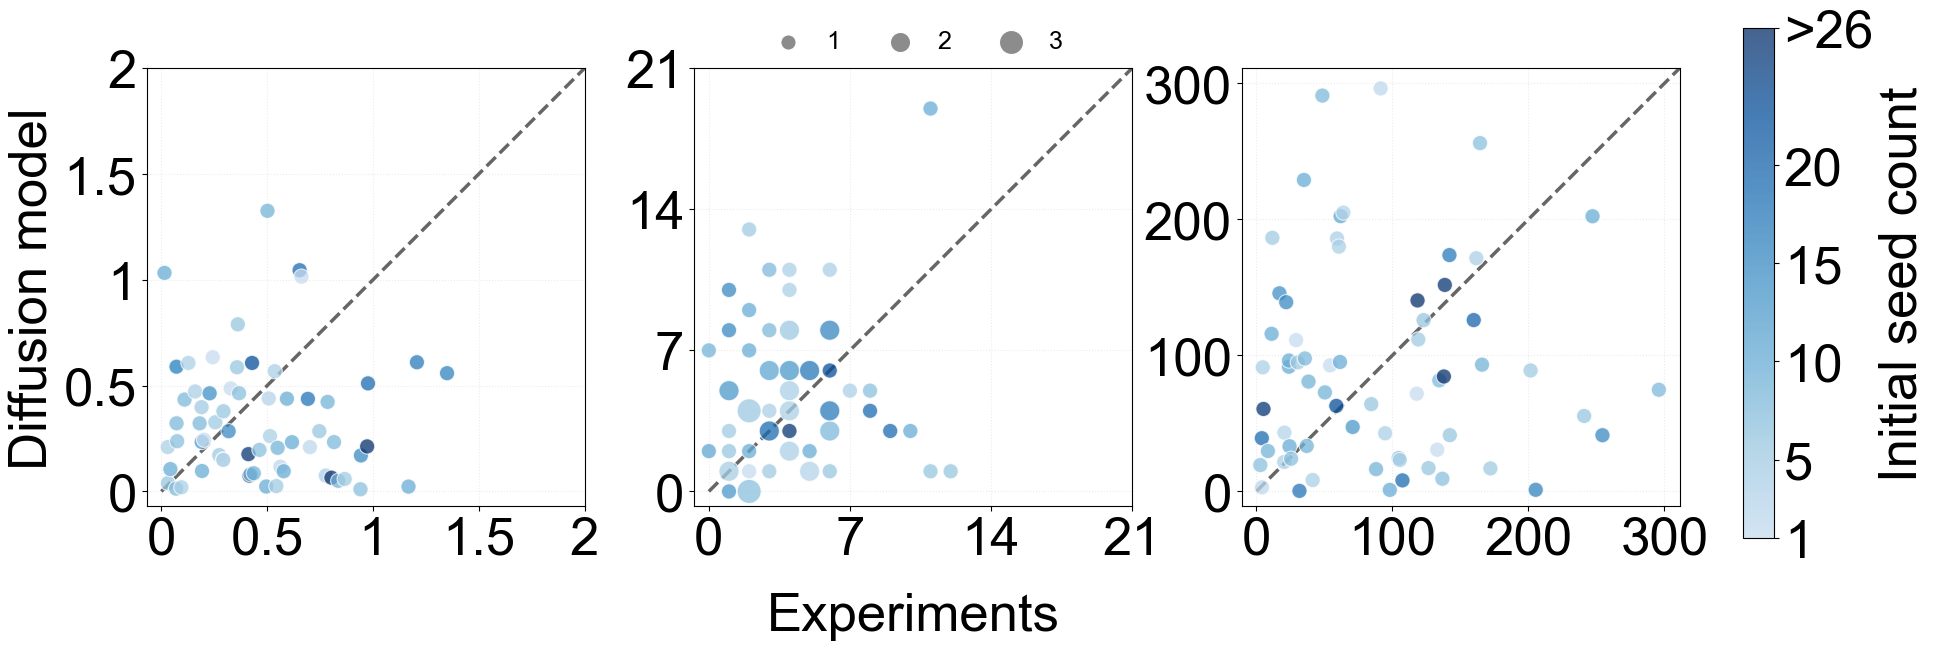

source,metric,metric_label,configuration_id,seed_count,diffusion_absolute_difference,experiment_absolute_difference,seed_count_plot,seed_count_group
0,branch_tip_count,Number of branch tips,196,2,1.000000,1.000000,2,2
1,branch_tip_count,Number of branch tips,197,8,8.000000,3.000000,8,8
2,branch_tip_count,Number of branch tips,198,1,4.000000,2.000000,1,1
3,branch_tip_count,Number of branch tips,199,6,2.000000,4.000000,6,6
4,branch_tip_count,Number of branch tips,200,4,11.000000,6.000000,4,4
...,...,...,...,...,...,...,...,...
190,total_skeleton_length_mm,Total skeleton length,Fixed_5,13,47.374205,70.821197,13,13
191,total_skeleton_length_mm,Total skeleton length,Fixed_6,14,145.621448,16.963952,14,14
192,total_skeleton_length_mm,Total skeleton length,Fixed_7,23,62.879150,58.788474,23,23
193,total_skeleton_length_mm,Total skeleton length,Fixed_8,11,202.364585,61.941087,11,11


In [18]:
# Raw absolute differences between replicate plates; blue colorbar.
# Shared setup for this plot and the final Supplementary Figure 16C ratio.

REPLICATE_SOURCES = ['Experiment', 'Diffusion']
replicate_metric_specs = [
    (f'mean_terminal_width_{PHYSICAL_UNIT}' if PIXEL_SIZE is not None
     else 'mean_terminal_width_px', 'Mean branch width'),
    ('branch_tip_count', 'Number of branch tips'),
    (f'total_skeleton_length_{PHYSICAL_UNIT}' if PIXEL_SIZE is not None
     else 'total_skeleton_length_px', 'Total skeleton length'),
]


replicate_plate_df = plate_df[plate_df['source'].isin(REPLICATE_SOURCES)].copy()
replicate_plate_df['configuration_id'] = (
    replicate_plate_df['image_id'].str.rsplit('_', n=1).str[0]
)

seed_color_min, seed_color_max = 1, 27

def mean_pairwise_absolute_difference(values):
    """Mean absolute difference across every valid replicate pair."""
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) < 2:
        return np.nan

    differences = []
    for first_index in range(len(values) - 1):
        for second_index in range(first_index + 1, len(values)):
            differences.append(abs(values[first_index] - values[second_index]))
    return float(np.mean(differences))


absolute_difference_records = []
for metric, metric_label in replicate_metric_specs:
    for (source, configuration_id), group in replicate_plate_df.groupby(
        ['source', 'configuration_id'], sort=False
    ):
        values = group[metric].dropna().to_numpy(float)
        if len(values) < 2:
            continue
        absolute_difference_records.append({
            'metric': metric,
            'metric_label': metric_label,
            'source': source,
            'configuration_id': configuration_id,
            'seed_count': group['seed_count'].iloc[0],
            'replicate_count': len(values),
            'absolute_difference': mean_pairwise_absolute_difference(values),
        })

absolute_difference_long_df = pd.DataFrame(absolute_difference_records)
absolute_difference_df = (
    absolute_difference_long_df.pivot(
        index=['metric', 'metric_label', 'configuration_id', 'seed_count'],
        columns='source', values='absolute_difference',
    )
    .dropna(subset=REPLICATE_SOURCES)
    .reset_index()
    .rename(columns={
        'Experiment': 'experiment_absolute_difference',
        'Diffusion': 'diffusion_absolute_difference',
    })
)

if absolute_difference_df.empty:
    raise ValueError('No configurations have at least two valid replicates in both sources.')

add_seed_count_plot_columns(absolute_difference_df)

BUBBLE_BASE_AREA = 120
BUBBLE_AREA_PER_EXTRA_CONFIGURATION = 90
SEED_COLORMAP_BOTTOM = 0.25
seed_count_colormap = ListedColormap(
    plt.cm.Blues(np.linspace(SEED_COLORMAP_BOTTOM, 1.0, 256)),
    name='truncated_blues',
)
ABSOLUTE_DIFFERENCE_TICKS = [
    [0, 0.5, 1, 1.5, 2],
    [0, 7, 14, 21],
    [0, 100, 200, 300],
]

fig, axes = plt.subplots(1, 3, figsize=(21, 8.5))
scatter_artist = None
for ax, (metric, metric_label), specified_ticks in zip(
    axes, replicate_metric_specs, ABSOLUTE_DIFFERENCE_TICKS
):
    plot_data = absolute_difference_df[absolute_difference_df['metric'] == metric]
    bubble_data = (
        plot_data.groupby([
            'experiment_absolute_difference', 'diffusion_absolute_difference'
        ], as_index=False)
        .agg(
            configuration_count=('configuration_id', 'size'),
            seed_count_plot=('seed_count_plot', 'mean'),
        )
    )
    x = bubble_data['experiment_absolute_difference'].to_numpy(float)
    y = bubble_data['diffusion_absolute_difference'].to_numpy(float)
    bubble_areas = (
        BUBBLE_BASE_AREA
        + BUBBLE_AREA_PER_EXTRA_CONFIGURATION
        * (bubble_data['configuration_count'].to_numpy(float) - 1)
    )

    # make colormap range shorter so the color differences are more noticeable
    

    scatter_artist = ax.scatter(
        x, y, c=bubble_data['seed_count_plot'], cmap=seed_count_colormap,
        vmin=seed_color_min, vmax=seed_color_max,
        s=bubble_areas, alpha=0.75, edgecolor='white', linewidth=0.8, zorder=3,
    )
    data_max = max(np.max(x), np.max(y)) if len(bubble_data) else 0.0
    axis_max = max(specified_ticks[-1], data_max * 1.05)
    axis_padding = 0.035 * axis_max
    ax.plot([0, axis_max], [0, axis_max], '--', color='0.4', linewidth=2.5)
    ax.set_xlim(-axis_padding, axis_max)
    ax.set_ylim(-axis_padding, axis_max)
    ax.set_xticks(specified_ticks)
    ax.set_yticks(specified_ticks)
    ax.xaxis.set_major_formatter(ticker.FormatStrFormatter('%g'))
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%g'))
    ax.set_aspect('equal', adjustable='box')
    ax.tick_params(axis='both', labelsize=KDE_TICK_FONTSIZE)
    ax.grid(True, linestyle=':', alpha=0.25)

# Bubble area shows how many configurations occupy an identical coordinate.
observed_overlap_counts = sorted(
    absolute_difference_df.groupby([
        'metric', 'experiment_absolute_difference', 'diffusion_absolute_difference'
    ]).size().unique()
)
if len(observed_overlap_counts) > 3:
    observed_overlap_counts = [
        observed_overlap_counts[0],
        observed_overlap_counts[len(observed_overlap_counts) // 2],
        observed_overlap_counts[-1],
    ]
if max(observed_overlap_counts, default=1) > 1:
    bubble_legend_handles = [
        axes[1].scatter(
            [], [],
            s=BUBBLE_BASE_AREA + BUBBLE_AREA_PER_EXTRA_CONFIGURATION * (count - 1),
            color='0.55', edgecolor='white', linewidth=0.8,
            label=str(count),
        )
        for count in observed_overlap_counts
    ]
    axes[1].legend(
        handles=bubble_legend_handles,
        loc='lower center', bbox_to_anchor=(0.5, 1.0),
        ncol=len(bubble_legend_handles), columnspacing=1.4, handletextpad=0.5,
        fontsize=18, frameon=False, borderaxespad=0.2,
    )

axes[0].set_ylabel('Diffusion model', fontsize=KDE_LABEL_FONTSIZE)
fig.supxlabel(
    'Experiments', x=0.495, y=0.17, fontsize=KDE_LABEL_FONTSIZE,
)
fig.subplots_adjust(left=0.13, right=0.86, bottom=0.29, top=0.88, wspace=0.25)
if scatter_artist is not None:
    colorbar_axis = fig.add_axes([0.89, 0.29, 0.015, 0.60])
    colorbar = fig.colorbar(scatter_artist, cax=colorbar_axis)
    configure_seed_count_colorbar(colorbar)
    colorbar.set_label('Initial seed count', fontsize=KDE_LABEL_FONTSIZE)
    colorbar.ax.tick_params(labelsize=KDE_TICK_FONTSIZE)

save_figure(fig, 'experimental_vs_diffusion_replicate_absolute_difference')
plt.show()

display(absolute_difference_df)


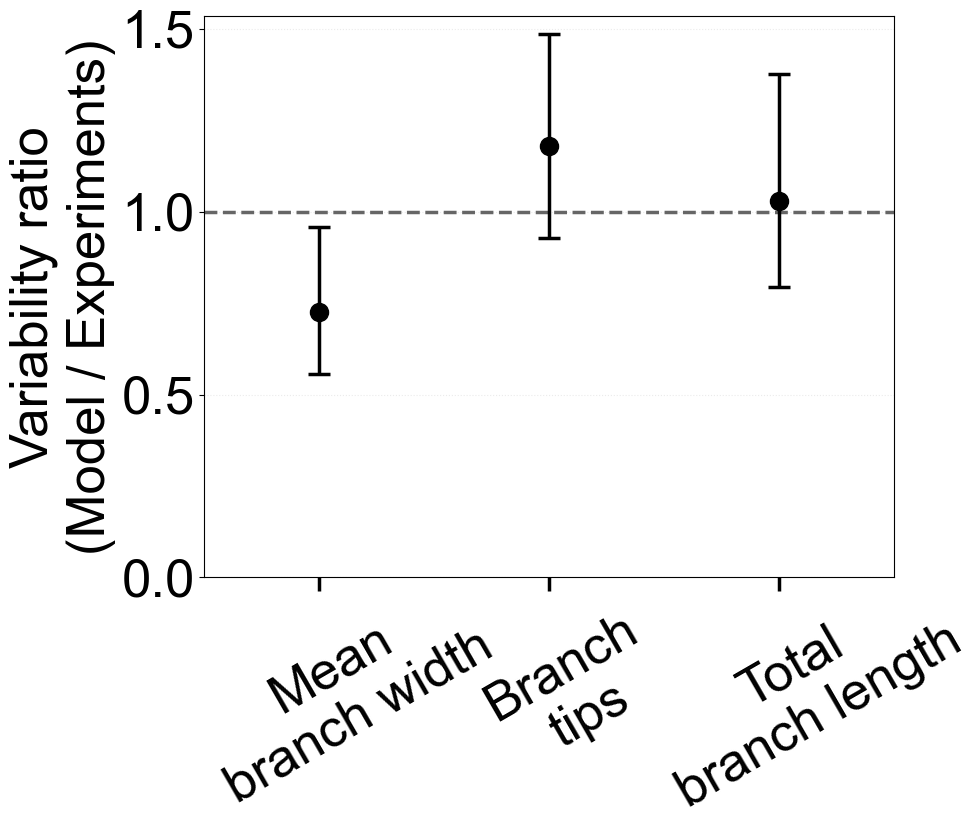

,metric_number,metric,metric_label,configuration_count,experimental_mean_absolute_difference,diffusion_mean_absolute_difference,diffusion_minus_experiment,variability_ratio,ratio_ci_lower,ratio_ci_upper
0,1,mean_terminal_width_mm,Mean branch width,65,0.461821,0.335463,-0.126358,0.726392,0.556271,0.957054
1,2,branch_tip_count,Number of branch tips,65,4.030769,4.753846,0.723077,1.179389,0.928559,1.486854
2,3,total_skeleton_length_mm,Total skeleton length,65,87.882770,90.382307,2.499537,1.028442,0.794052,1.376974


In [19]:
# Aggregate stochastic-variability comparison.
# Ratio = mean diffusion absolute replicate difference /
#         mean experimental absolute replicate difference.
# Confidence intervals resample matched seed configurations.
ratio_rng = np.random.default_rng(RANDOM_SEED)
ratio_summary_records = []
ratio_tail = (1 - CONFIDENCE_LEVEL) / 2

for metric_number, (metric, metric_label) in enumerate(
    replicate_metric_specs, start=1
):
    metric_data = (
        absolute_difference_df.loc[
            absolute_difference_df['metric'] == metric
        ]
        .sort_values('configuration_id')
        .reset_index(drop=True)
    )
    experimental = metric_data['experiment_absolute_difference'].to_numpy(float)
    diffusion = metric_data['diffusion_absolute_difference'].to_numpy(float)
    experimental_mean = experimental.mean()
    diffusion_mean = diffusion.mean()
    variability_ratio = (
        diffusion_mean / experimental_mean
        if experimental_mean > 0 else np.nan
    )

    bootstrap_indices = ratio_rng.integers(
        0, len(metric_data),
        size=(BOOTSTRAP_REPEATS, len(metric_data)),
    )
    bootstrap_experimental_means = experimental[bootstrap_indices].mean(axis=1)
    bootstrap_diffusion_means = diffusion[bootstrap_indices].mean(axis=1)
    valid_bootstraps = bootstrap_experimental_means > 0
    bootstrap_ratios = (
        bootstrap_diffusion_means[valid_bootstraps]
        / bootstrap_experimental_means[valid_bootstraps]
    )
    if len(bootstrap_ratios):
        ratio_ci_lower, ratio_ci_upper = np.quantile(
            bootstrap_ratios, [ratio_tail, 1 - ratio_tail]
        )
    else:
        ratio_ci_lower = ratio_ci_upper = np.nan

    ratio_summary_records.append({
        'metric_number': metric_number,
        'metric': metric,
        'metric_label': metric_label,
        'configuration_count': len(metric_data),
        'experimental_mean_absolute_difference': experimental_mean,
        'diffusion_mean_absolute_difference': diffusion_mean,
        'diffusion_minus_experiment': diffusion_mean - experimental_mean,
        'variability_ratio': variability_ratio,
        'ratio_ci_lower': ratio_ci_lower,
        'ratio_ci_upper': ratio_ci_upper,
    })

replicate_variability_ratio_df = pd.DataFrame(ratio_summary_records)

fig, ax = plt.subplots(figsize=(10, 8.5))
x = replicate_variability_ratio_df['metric_number'].to_numpy(float)
ratio = replicate_variability_ratio_df['variability_ratio'].to_numpy(float)
lower = replicate_variability_ratio_df['ratio_ci_lower'].to_numpy(float)
upper = replicate_variability_ratio_df['ratio_ci_upper'].to_numpy(float)
ratio_error = np.maximum(0, np.vstack([ratio - lower, upper - ratio]))

ax.axhline(1, color='0.4', linestyle='--', linewidth=2.5, zorder=1)
ax.errorbar(
    x, ratio, yerr=ratio_error, fmt='o',
    color='black', ecolor='black', markersize=13,
    elinewidth=2.5, capsize=8, capthick=2.5, zorder=3,
)
ax.set_xlim(0.5, 3.5)
ax.set_ylim(bottom=0)
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(['Mean\nbranch width', 'Branch\ntips', 'Total\nbranch length'], fontsize=KDE_TICK_FONTSIZE)
# make just xtick locations bold, not text
for tick in ax.get_xticklines():
    tick.set_markeredgewidth(2.5)
ax.tick_params(
    axis='x', pad=40, labelsize=KDE_TICK_FONTSIZE,
    length=10, width=2.5, color='black', direction='out',
)
ax.tick_params(axis='y', labelsize=KDE_TICK_FONTSIZE)
# align x ticks at 30 degree angle such that center of the labels is aligned with the tick marks
plt.setp(
    ax.get_xticklabels(), rotation=30, ha='center', va='top',
    rotation_mode='anchor',
)
ax.set_ylabel(
    'Variability ratio\n(Model / Experiments)',
    fontsize=KDE_LABEL_FONTSIZE,
)
ax.grid(axis='y', linestyle=':', alpha=0.25)
ax.set_axisbelow(True)
fig.subplots_adjust(left=0.27, right=0.96, bottom=0.30, top=0.96)
save_figure(fig, 'replicate_variability_ratio')
plt.show()

display(replicate_variability_ratio_df)


In [20]:
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Vector PDF export: Supp. Fig. 16C — generated/experimental variability ratio
# Run immediately after the preceding plotting/analysis cell.
from pathlib import Path
import runpy as _vector_runpy

# Locate the project from the notebook working directory; no sys.path changes.
VECTOR_PROJECT_ROOT = next(
    _p for _p in (Path.cwd(), *Path.cwd().parents)
    if (_p / 'figure_exports').is_dir()
)
save_vector_pdf = vars(_figure_exports)['save_vector_pdf']
VECTOR_DIR = VECTOR_PROJECT_ROOT / 'sim_to_exp_diffusion' / 'vector based plots'

save_vector_pdf(fig, VECTOR_DIR / 'SuppFig16C_replicate_variability_ratio.pdf')


Saved vector PDF: /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/vector based plots/SuppFig16C_replicate_variability_ratio.pdf


PosixPath('/hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/vector based plots/SuppFig16C_replicate_variability_ratio.pdf')